# Chapter 12

Python version of the R code for Chapter 12 of *In All Likelihood* (Pawitan, 2001).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize

from helpers import scan

## Example 12.1 (`EX12-1.R`)

In [2]:
y = np.array([10, 22, 15, 23, 17], dtype=float)
x1 = np.array([1, -1, 1, -1, 1])
x2 = np.array([1, 1, 0, 0, -1])
x3 = np.array([0, 0, 1, 1, -1])

X = np.column_stack([np.ones(5), x1, x2, x3])
ylm, *_ = np.linalg.lstsq(X, y, rcond=None)
print(ylm)


def fn(p):
    return np.sum((y - p[0] - p[1] * x1 - p[2] * x2 - p[3] * x3) ** 2)


a = optimize.minimize(fn, [y.mean(), 0, 0, 0])
print(a.x)

# iterative solution:
y23 = y.mean()
for i in range(1, 26):
    yc = np.append(y, y23)
    M = yc.reshape(3, 2).T  # 2 x 3 table, filled by column as in R
    a = M.mean(axis=1) - yc.mean()
    b = M.mean(axis=0) - yc.mean()
    y23 = yc.mean() + a[1] + b[2]
    print(np.round([i, yc.mean(), a[0], b[0], b[1]], 3))

[ 1.90000000e+01 -5.00000000e+00 -3.00000000e+00 -1.03272361e-15]
[ 1.90000000e+01 -4.99999999e+00 -2.99999998e+00  1.16678711e-08]
[ 1.  17.4 -3.4 -1.4  1.6]
[ 2.    17.933 -3.933 -1.933  1.067]
[ 3.    18.289 -4.289 -2.289  0.711]
[ 4.    18.526 -4.526 -2.526  0.474]
[ 5.    18.684 -4.684 -2.684  0.316]
[ 6.    18.789 -4.789 -2.789  0.211]
[ 7.   18.86 -4.86 -2.86  0.14]
[ 8.    18.906 -4.906 -2.906  0.094]
[ 9.    18.938 -4.938 -2.938  0.062]
[10.    18.958 -4.958 -2.958  0.042]
[11.    18.972 -4.972 -2.972  0.028]
[ 1.2000e+01  1.8982e+01 -4.9820e+00 -2.9820e+00  1.8000e-02]
[ 1.3000e+01  1.8988e+01 -4.9880e+00 -2.9880e+00  1.2000e-02]
[ 1.4000e+01  1.8992e+01 -4.9920e+00 -2.9920e+00  8.0000e-03]
[ 1.5000e+01  1.8995e+01 -4.9950e+00 -2.9950e+00  5.0000e-03]
[ 1.6000e+01  1.8996e+01 -4.9960e+00 -2.9960e+00  4.0000e-03]
[ 1.7000e+01  1.8998e+01 -4.9980e+00 -2.9980e+00  2.0000e-03]
[ 1.8000e+01  1.8998e+01 -4.9980e+00 -2.9980e+00  2.0000e-03]
[ 1.9000e+01  1.8999e+01 -4.9990e+00 -2.99

## Example 12.2 and Figure 12.1 (`EX12-2.R`)

Illustration of the EM algorithm.

[0.2   0.544 0.615 0.625 0.627 0.627]


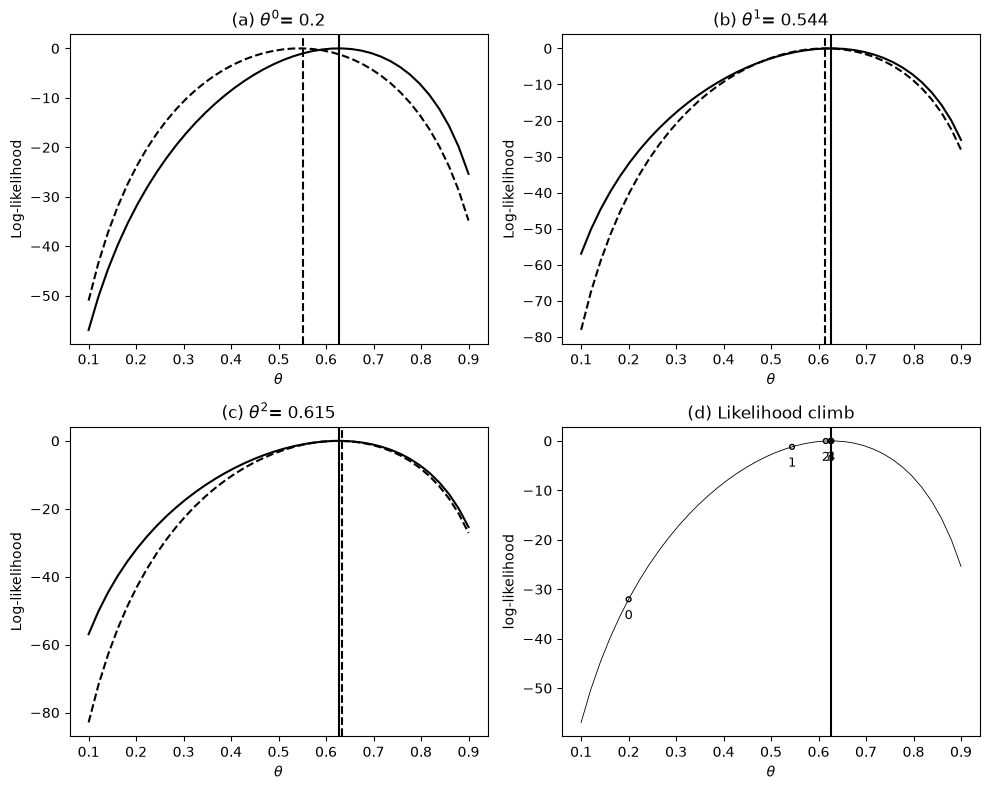

In [3]:
y = np.array([125, 18, 20, 34])
phat = [0.2]
x = np.array([0, 0, 18, 20, 34], dtype=float)
for i in range(5):
    x[0] = .5 / (.5 + phat[i] / 4) * y[0]
    x[1] = y[0] - x[0]
    phat.append((x[1] + x[4]) / (x.sum() - x[0]))
phat = np.array(phat)
print(np.round(phat, 3))

p = np.linspace(.1, .9, 40)
l1 = y[0] * np.log(.5 + p / 4) + (y[1] + y[2]) * np.log(1 - p) + y[3] * np.log(p)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

titles = [r"(a) $\theta^0$= 0.2", r"(b) $\theta^1$= 0.544", r"(c) $\theta^2$= 0.615"]
for i in range(3):
    x[0] = .5 / (.5 + phat[i] / 4) * y[0]
    x[1] = y[0] - x[0]
    l2 = (x[1] + x[4]) * np.log(p) + (x[2] + x[3]) * np.log(1 - p)
    ax = axes[i]
    ax.plot(p, l1 - l1.max(), "k-")
    ax.plot(p, l2 - l2.max(), "k--")
    ax.axvline(p[l2 == l2.max()].min(), color="k", ls="--")
    ax.axvline(.627, color="k")
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("Log-likelihood")
    ax.set_title(titles[i])

lp = y[0] * np.log(.5 + phat / 4) + (y[1] + y[2]) * np.log(1 - phat) + y[3] * np.log(phat)
lp = lp - lp.max()

ax = axes[3]
ax.plot(p, l1 - l1.max(), "k-", lw=0.6)
ax.scatter(phat, lp, s=12, facecolors="none", edgecolors="k")
for k, (ph, l) in enumerate(zip(phat, lp)):
    if k < 5:
        ax.text(ph, l - 4, str(k), fontsize=9, ha="center")
ax.axvline(.627, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("log-likelihood")
ax.set_title("(d) Likelihood climb")

fig.tight_layout()
plt.show()

## Example 12.3 (`EX12-3.R`)

Waiting times between eruptions of the famous Old Faithful geyser in
Yellowstone National Park.

1 [ 0.306 54.092  4.813 80.339  7.494]
2 [ 0.306 54.136  4.891 80.317  7.542]
3 [ 0.306 54.154  4.913 80.323  7.541]
4 [ 0.306 54.166  4.923 80.331  7.535]
5 [ 0.307 54.175  4.93  80.338  7.528]
6 [ 0.307 54.181  4.935 80.343  7.524]
7 [ 0.307 54.186  4.939 80.347  7.52 ]
8 [ 0.307 54.19   4.942 80.35   7.517]
9 [ 0.307 54.193  4.945 80.353  7.515]
10 [ 0.307 54.195  4.946 80.355  7.513]
11 [ 0.307 54.197  4.948 80.356  7.512]
12 [ 0.307 54.198  4.949 80.357  7.511]
13 [ 0.307 54.199  4.949 80.358  7.51 ]
14 [ 0.308 54.2    4.95  80.358  7.509]
15 [ 0.308 54.201  4.951 80.359  7.509]
16 [ 0.308 54.201  4.951 80.359  7.509]
17 [ 0.308 54.202  4.951 80.359  7.508]
18 [ 0.308 54.202  4.951 80.36   7.508]
19 [ 0.308 54.202  4.951 80.36   7.508]
20 [ 0.308 54.202  4.952 80.36   7.508]
21 [ 0.308 54.202  4.952 80.36   7.508]
22 [ 0.308 54.202  4.952 80.36   7.508]
23 [ 0.308 54.202  4.952 80.36   7.508]
24 [ 0.308 54.202  4.952 80.36   7.508]
25 [ 0.308 54.203  4.952 80.36   7.508]


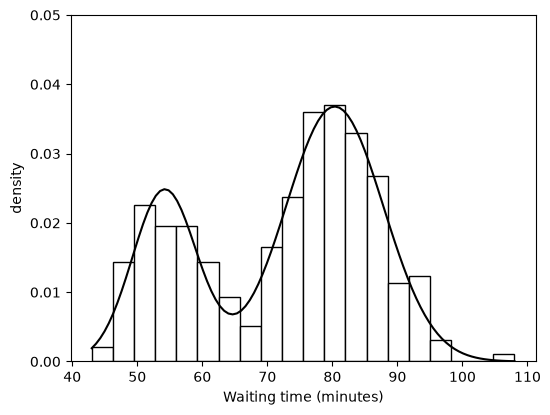

In [4]:
y = scan("geyser.dat")
n = len(y)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.hist(y, bins=20, density=True, color="w", edgecolor="k")
ax.set_ylim(0, .05)
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("density")

# starting values
p = 0.3
mu1 = 55
sig1 = 4
mu2 = 80
sig2 = 7

for i in range(1, 26):
    deny = p * stats.norm.pdf(y, mu1, sig1) + (1 - p) * stats.norm.pdf(y, mu2, sig2)
    p1 = p * stats.norm.pdf(y, mu1, sig1) / deny
    p2 = 1 - p1

    # updates:
    p = p1.sum() / n
    mu1 = np.sum(p1 * y) / p1.sum()
    mu2 = np.sum(p2 * y) / p2.sum()
    sig1 = np.sqrt(np.sum(p1 * (y - mu1) ** 2) / p1.sum())
    sig2 = np.sqrt(np.sum(p2 * (y - mu2) ** 2) / p2.sum())
    print(i, np.round([p, mu1, sig1, mu2, sig2], 3))

x = np.linspace(y.min(), y.max(), 100)
den = p * stats.norm.pdf(x, mu1, sig1) + (1 - p) * stats.norm.pdf(x, mu2, sig2)
ax.plot(x, den, "k-")
plt.show()